# Conditional GAN for QCD Background Modelling — ATLAS H→bb̄ Analysis
## UCL PHAS0052 Group Project — Group 35

---

### Overview

This notebook builds a **Conditional Generative Adversarial Network (cGAN)** to model the jet mass distribution of QCD background events in the ATLAS H→bb̄ analysis.

**Physics motivation:**  
The Higgs boson signal appears as a narrow peak near 125 GeV in the large-*R* jet mass spectrum. To extract it, we need an accurate model of the smooth QCD background. Instead of a simple parametric fit, the cGAN learns the full background shape from data, conditioned on jet substructure variables that correlate with mass.

**Strategy:**  
- Use only **Category A** conditioning variables — strongly correlated with mass and with similar signal/background distributions (KS < 0.2), ensuring no signal bias.  
- Train **two independent models** and compare their performance:  
  - **Model A**: trained on the **full mass range** (no blinding)  
  - **Model B**: trained on **sideband only** (100–150 GeV signal region excluded)  
- Comparing both models in the signal region reveals whether blinding is necessary — a key validation of the sideband training strategy.

---

### Notebook Structure

| Section | Description |
|---------|-------------|
| 1. Setup | Imports |
| 2. Variable Definitions | Corrected Category A variables (21 vars) |
| 3. Field Alias Map | ROOT branch name → short alias |
| 4. Data Loading | Load all background ROOT files |
| 5. Feature Extraction | Leading-jet selection |
| 6. Dataset Preparation | Full-range and sideband splits |
| 7. Model Architecture | Generator and Discriminator |
| 8. Training | Two-model training procedure |
| 9. Loss Curves | Training diagnostics |
| 10. Closure Tests | Real vs Generated comparison |
| 11. Signal Region Study | Full-range vs Sideband in signal region |
| 12. KS Evaluation | Multi-seed quantitative comparison |
| 13. Ablation Study | Optimal number of variables |
| 14. Baseline Comparison | vs Exponential fit |
| 15. Save Results | Export for report |


---
## 1. Setup

In [31]:
import uproot
import awkward as ak
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import glob

print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {'cuda' if torch.cuda.is_available() else 'cpu'}")

PyTorch version : 2.10.0+cpu
Device          : cpu


---
## 2. Variable Definitions

### Corrected Category A — Universal Predictors (21 variables)

Updated from the corrected intro notebook analysis (VS Code run). These 21 variables satisfy:
- Background Pearson correlation with mass: |r| > 0.3
- KS statistic between signal and background distributions: **KS < 0.2**

Variables previously misclassified as Category A (e.g. `tau1`, `width`, `ecfg_2_1`, `rg`) have been  
reclassified to Category B (KS ≥ 0.2) and are excluded here.

In [32]:
# Category A variables: corrected from intro notebook (21 variables, KS < 0.2)
# Ordered by background Pearson correlation strength (strongest first)
category_a_vars = [
    "ecf2",          # |r| = 0.904  KS = 0.196
    "split12",       # |r| = 0.884  KS = 0.047
    "qw",            # |r| = 0.810  KS = 0.084
    "ghosttrackcount",                              # |r| = 0.802  KS = 0.129
    "ghostantiktvr30rmax4rmin02pv0trackjetscount",  # |r| = 0.763  KS = 0.082
    "split23",       # |r| = 0.718  KS = 0.048
    "split34",       # |r| = 0.714  KS = 0.055
    "ecf3",          # |r| = 0.682  KS = 0.108
    "foxwolfram2",   # |r| = 0.584  KS = 0.072
    "foxwolfram4",   # |r| = 0.560  KS = 0.056
    "zg",            # |r| = 0.526  KS = 0.151
    "zcut12",        # |r| = 0.512  KS = 0.165
    "tau21",         # |r| = 0.459  KS = 0.052
    "tau21_wta",     # |r| = 0.444  KS = 0.070
    "d2",            # |r| = 0.396  KS = 0.145
    "n2",            # |r| = 0.382  KS = 0.040
    "thrustmin",     # |r| = 0.361  KS = 0.010
    "zcut23",        # |r| = 0.352  KS = 0.147
    "thrustmaj",     # |r| = 0.321  KS = 0.018
    "aplanarity",    # |r| = 0.311  KS = 0.034
    "sphericity",    # |r| = 0.303  KS = 0.015
]

print(f"Category A variables: {len(category_a_vars)}")

Category A variables: 21


---
## 3. Field Alias Map

Mapping from full ATLAS ROOT branch names to short aliases used throughout this notebook.

In [33]:
field_aliases_all = {
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetMass": "mass",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt":   "pt",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GhostBHadronsFinal":                       "ghost_bhadrons",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF1":      "ecf1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF2":      "ecf2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF3":      "ecf3",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Split12":   "split12",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Split23":   "split23",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Split34":   "split34",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Width":     "width",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.WidthPhi":  "widthphi",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau1":      "tau1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau2":      "tau2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau3":      "tau3",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau4":      "tau4",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau21":     "tau21",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau32":     "tau32",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau1_wta":  "tau1_wta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau2_wta":  "tau2_wta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau3_wta":  "tau3_wta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau4_wta":  "tau4_wta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau21_wta": "tau21_wta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.D2":        "d2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.C1":        "c1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.C2":        "c2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.N2":        "n2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Qw":        "qw",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Rg":        "rg",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Zg":        "zg",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.KtDR":      "ktdr",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Zcut12":    "zcut12",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Zcut23":    "zcut23",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GroomMRatio":  "groommratio",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ThrustMin":    "thrustmin",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ThrustMaj":    "thrustmaj",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Aplanarity":   "aplanarity",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Sphericity":   "sphericity",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.PlanarFlow":   "planarflow",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.FoxWolfram0":  "foxwolfram0",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.FoxWolfram2":  "foxwolfram2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.FoxWolfram4":  "foxwolfram4",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.EffNClusts":          "effnclusts",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.EffNClustsCaloBase":  "effnclustscalobased",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GhostTrackCount":     "ghosttrackcount",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_2_1":    "ecfg_2_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_2_1_2":  "ecfg_2_1_2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_1":    "ecfg_3_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_1_1":  "ecfg_3_1_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_2":    "ecfg_3_2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_2_1":  "ecfg_3_2_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_2_2":  "ecfg_3_2_2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_3_1":  "ecfg_3_3_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_3_3_2":  "ecfg_3_3_2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_4_2_2":  "ecfg_4_2_2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECFG_4_4_1":  "ecfg_4_4_1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GN2Xv01_phbb": "phbb",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GhostAntiKtVR30Rmax4Rmin02PV0TrackJetsCount": "ghostantiktvr30rmax4rmin02pv0trackjetscount",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ChargePtFrac": "chargeptfrac",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ChargeMFrac":  "chargemfrac",
}
print(f"Total aliases defined: {len(field_aliases_all)}")

Total aliases defined: 59


---
## 4. Data Loading

All four background ROOT files are loaded from `./background/`. Only branches corresponding to  
Category A variables plus `mass`, `pt`, and `ghost_bhadrons` are read.

> **No b-hadron filter is applied to background.**  
> This filter selects jets containing a real b-hadron and is physically meaningful only for  
> H→bb̄ signal events. Applying it to QCD background would discard ~99% of events, leaving  
> only a rare b-enriched subset whose mass distribution resembles the Higgs signal.

In [34]:
# Helper: rename long ROOT branch names to short aliases
def rename_fields(data, mapping):
    for long_name, short_name in mapping.items():
        if long_name in ak.fields(data):
            data[short_name] = data[long_name]
    keep = [v for v in mapping.values() if v in ak.fields(data)]
    return data[keep]

# Find all background ROOT files
bg_files = glob.glob("./background/*.root")
print(f"Found {len(bg_files)} background files:")
for f in bg_files:
    print(f"  {f}")

# Check which branches actually exist (avoids KeyInFileError)
sample_file    = uproot.open(f"{bg_files[0]}:CollectionTree")
available_keys = set(sample_file.keys())

fields_available = [f for f in field_aliases_all if f in available_keys]
fields_missing   = [f for f in field_aliases_all if f not in available_keys]

if fields_missing:
    print(f"\nSkipping {len(fields_missing)} branches not in ROOT file:")
    for f in fields_missing:
        print(f"  ✗ {f.split('.')[-1]}")

print(f"\nLoading {len(fields_available)} branches from {len(bg_files)} files...")

data_bkg = uproot.concatenate(
    "./background/*.root:CollectionTree",
    fields_available, library="ak")

data_bkg = rename_fields(data_bkg, field_aliases_all)
print(f"\nLoaded fields : {list(ak.fields(data_bkg))}")
print(f"Total events  : {len(data_bkg):,}")

Found 4 background files:
  ./background\DAOD_FTAG1.35981770._000001.pool.root
  ./background\DAOD_FTAG1.35981770._000002.pool.root
  ./background\DAOD_FTAG1.35981770._000003.pool.root
  ./background\DAOD_FTAG1.35981770._000004.pool.root

Skipping 7 branches not in ROOT file:
  ✗ Rg
  ✗ Zg
  ✗ Zcut12
  ✗ Zcut23
  ✗ GroomMRatio
  ✗ EffNClustsCaloBase
  ✗ ChargePtFrac

Loading 52 branches from 4 files...

Loaded fields : ['mass', 'pt', 'ghost_bhadrons', 'ecf1', 'ecf2', 'ecf3', 'split12', 'split23', 'split34', 'width', 'widthphi', 'tau1', 'tau2', 'tau3', 'tau4', 'tau21', 'tau32', 'tau1_wta', 'tau2_wta', 'tau3_wta', 'tau4_wta', 'tau21_wta', 'd2', 'c1', 'c2', 'n2', 'qw', 'ktdr', 'thrustmin', 'thrustmaj', 'aplanarity', 'sphericity', 'planarflow', 'foxwolfram0', 'foxwolfram2', 'foxwolfram4', 'effnclusts', 'ghosttrackcount', 'ecfg_2_1', 'ecfg_2_1_2', 'ecfg_3_1', 'ecfg_3_1_1', 'ecfg_3_2', 'ecfg_3_2_1', 'ecfg_3_2_2', 'ecfg_3_3_1', 'ecfg_3_3_2', 'ecfg_4_2_2', 'ecfg_4_4_1', 'phbb', 'ghostantiktvr3

---
## 5. Leading Jet Extraction

Each event contains multiple large-*R* jets. We select the **leading jet** (highest pT) per event,  
consistent with the intro notebook analysis. Momenta are converted from MeV to GeV.

In [35]:
# Select leading (highest-pT) jet per event
leading_idx = ak.argmax(data_bkg["pt"], axis=-1, keepdims=True)

def extract_leading_var(data, var):
    vals = ak.flatten(data[var][leading_idx], axis=-1)
    return ak.to_numpy(ak.fill_none(vals, np.nan))

leading = {}
for var in ak.fields(data_bkg):
    if var == "ghost_bhadrons":
        continue
    arr = extract_leading_var(data_bkg, var)
    if var in ["mass", "pt"]:
        arr = arr / 1000.0  # MeV → GeV
    leading[var] = arr

# Keep only Category A variables that were actually loaded
category_a_vars = [v for v in category_a_vars if v in leading]

print(f"Leading jet variables extracted : {len(leading)}")
print(f"Usable Category A variables     : {len(category_a_vars)}")
print(f"  → {category_a_vars}")

Leading jet variables extracted : 51
Usable Category A variables     : 18
  → ['ecf2', 'split12', 'qw', 'ghosttrackcount', 'ghostantiktvr30rmax4rmin02pv0trackjetscount', 'split23', 'split34', 'ecf3', 'foxwolfram2', 'foxwolfram4', 'tau21', 'tau21_wta', 'd2', 'n2', 'thrustmin', 'thrustmaj', 'aplanarity', 'sphericity']


---
## 6. Dataset Preparation

### 6a. Feature Matrix and Quality Cuts

In [36]:
mass_raw = leading["mass"].astype(np.float32)
X_full   = np.column_stack([leading[v] for v in category_a_vars]).astype(np.float32)

# Remove NaN/Inf and unphysical mass values
mask   = np.isfinite(mass_raw) & np.all(np.isfinite(X_full), axis=1) & (mass_raw > 0)
X_full = X_full[mask]
y_full = mass_raw[mask]

print(f"Events after quality cuts : {len(y_full):,}")
print(f"Feature matrix shape      : {X_full.shape}")
print(f"Mass range                : {y_full.min():.1f} — {y_full.max():.1f} GeV")

Events after quality cuts : 79,997
Feature matrix shape      : (79997, 18)
Mass range                : 0.1 — 721.5 GeV


### 6b. Signal Region Definition

```
|←── sideband ──→|←── signal region ──→|←── sideband ──→|
0               100                   150              500  GeV
```

Two datasets are prepared for the two-model comparison:
- **Full range**: all events (used to train Model A)
- **Sideband only**: events with mass < 100 GeV or > 150 GeV (used to train Model B)

In [37]:
SIGNAL_LO = 100.0  # GeV — lower boundary of Higgs signal region
SIGNAL_HI = 150.0  # GeV — upper boundary of Higgs signal region

sideband_mask = (y_full < SIGNAL_LO) | (y_full > SIGNAL_HI)
X_sb = X_full[sideband_mask]
y_sb = y_full[sideband_mask]

n_sig = (~sideband_mask).sum()
print(f"Full dataset       : {len(y_full):>8,} events")
print(f"Sideband only      : {len(y_sb):>8,} events")
print(f"Signal region      : {n_sig:>8,} events ({100*n_sig/len(y_full):.1f}%)")

Full dataset       :   79,997 events
Sideband only      :   70,049 events
Signal region      :    9,948 events (12.4%)


### 6c. Train / Validation / Test Splits

Both models use the **same 70/15/15 random split** for fair comparison.  
Scalers are fitted only on the training set to prevent data leakage.

In [38]:
def make_splits(X, y, random_state=42):
    """70/15/15 split + StandardScaler. Returns scaled arrays and scalers."""
    X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.15, random_state=random_state)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.17647, random_state=random_state)

    sX = StandardScaler(); sy = StandardScaler()
    X_tr_s = sX.fit_transform(X_tr).astype(np.float32)
    X_va_s = sX.transform(X_va).astype(np.float32)
    X_te_s = sX.transform(X_te).astype(np.float32)
    y_tr_s = sy.fit_transform(y_tr.reshape(-1,1)).astype(np.float32).squeeze()
    y_va_s = sy.transform(y_va.reshape(-1,1)).astype(np.float32).squeeze()

    return (X_tr_s, X_va_s, X_te_s,
            y_tr_s, y_va_s, y_te,   # y_te kept in GeV for evaluation
            sX, sy)

# Model A: full range
(XA_tr, XA_va, XA_te,
 yA_tr, yA_va, yA_te,
 sX_A, sy_A) = make_splits(X_full, y_full)

# Model B: sideband only
(XB_tr, XB_va, XB_te,
 yB_tr, yB_va, yB_te,
 sX_B, sy_B) = make_splits(X_sb, y_sb)

n_vars = XA_tr.shape[1]
print(f"Model A (full range) — Train: {len(yA_tr):,}  Val: {len(yA_va):,}  Test: {len(yA_te):,}")
print(f"Model B (sideband)   — Train: {len(yB_tr):,}  Val: {len(yB_va):,}  Test: {len(yB_te):,}")
print(f"Conditioning variables: {n_vars}")

Model A (full range) — Train: 55,997  Val: 12,000  Test: 12,000
Model B (sideband)   — Train: 49,033  Val: 10,508  Test: 10,508
Conditioning variables: 18


---
## 7. PyTorch DataLoader

In [39]:
class JetDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

def make_loader(X, y, batch_size=1024, shuffle=True):
    return DataLoader(JetDataset(X, y), batch_size=batch_size,
                      shuffle=shuffle, drop_last=shuffle)

---
## 8. Model Architecture

### Generator
Takes conditioning variables `x` + random noise `z` → synthetic jet mass.

### Discriminator  
Takes conditioning variables `x` + a mass value (real or generated) → real/fake logit.

```
Generator  : [x (n_vars) | z (8)] → Linear(128) → LeakyReLU → Linear(128) → LeakyReLU → Linear(1)
Discriminator: [x (n_vars) | mass] → Linear(128) → LeakyReLU → Linear(128) → LeakyReLU → Linear(1)
```

In [40]:
class Generator(nn.Module):
    def __init__(self, n_vars, z_dim=8):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(n_vars + z_dim, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128),            nn.LeakyReLU(0.2),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        z = torch.randn(x.size(0), self.z_dim, device=x.device)
        return self.net(torch.cat([x, z], dim=1)).squeeze(-1)

class Discriminator(nn.Module):
    def __init__(self, n_vars):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_vars + 1, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128),        nn.LeakyReLU(0.2),
            nn.Linear(128, 1)
        )
    def forward(self, x, mass):
        return self.net(torch.cat([x, mass.unsqueeze(1)], dim=1)).squeeze(-1)

print(f"Generator params    : {sum(p.numel() for p in Generator(n_vars).parameters()):,}")
print(f"Discriminator params: {sum(p.numel() for p in Discriminator(n_vars).parameters()):,}")

Generator params    : 20,097
Discriminator params: 19,201


---
## 9. Training

### Training Procedure

At each mini-batch:
1. **Train D**: real pairs → label 1, generated pairs → label 0; minimise BCE  
2. **Train G**: generate fakes, maximise D's confusion (target label 1)

**Convergence indicator**: both D and G losses stabilise near ln(2) ≈ 0.693,  
meaning the Discriminator can no longer distinguish real from generated events.

In [41]:
def train_cgan(X_tr, y_tr, X_va, y_va,
               n_vars, epochs=50, lr=2e-4, batch_size=1024, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    G = Generator(n_vars).to(device)
    D = Discriminator(n_vars).to(device)
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce  = nn.BCEWithLogitsLoss()

    loader_tr = make_loader(X_tr, y_tr)
    loader_va = make_loader(X_va, y_va, shuffle=False)
    history   = {"lossG_train": [], "lossD_train": [], "lossG_val": []}

    for epoch in range(epochs):
        G.train(); D.train()
        g_b, d_b = [], []
        for x, y in loader_tr:
            x, y = x.to(device), y.to(device)
            fake   = G(x).detach()
            lossD  = bce(D(x, y), torch.ones_like(y)) + bce(D(x, fake), torch.zeros_like(fake))
            optD.zero_grad(); lossD.backward(); optD.step()
            fake   = G(x)
            lossG  = bce(D(x, fake), torch.ones_like(fake))
            optG.zero_grad(); lossG.backward(); optG.step()
            d_b.append(lossD.item()); g_b.append(lossG.item())

        G.eval()
        gv = []
        with torch.no_grad():
            for x, y in loader_va:
                x = x.to(device)
                gv.append(bce(D(x, G(x)), torch.ones(x.size(0), device=device)).item())

        history["lossD_train"].append(np.mean(d_b))
        history["lossG_train"].append(np.mean(g_b))
        history["lossG_val"].append(np.mean(gv))

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d}/{epochs}  "
                  f"D={np.mean(d_b):.4f}  G={np.mean(g_b):.4f}  G_val={np.mean(gv):.4f}")
    return G, device, history

def generate_mass(G, X_te_s, scaler_y, device):
    G.eval()
    with torch.no_grad():
        fake_s = G(torch.from_numpy(X_te_s).to(device)).cpu().numpy()
    return scaler_y.inverse_transform(fake_s.reshape(-1,1)).squeeze()

### Train Model A — Full Range

In [42]:
print("=" * 60)
print(f"MODEL A: Full range training ({len(yA_tr):,} events)")
print("=" * 60)
G_A, device, hist_A = train_cgan(XA_tr, yA_tr, XA_va, yA_va, n_vars=n_vars, epochs=50, seed=42)

MODEL A: Full range training (55,997 events)
Epoch   1/50  D=1.3764  G=0.7036  G_val=0.6891
Epoch  10/50  D=1.3836  G=0.6962  G_val=0.6912
Epoch  20/50  D=1.3844  G=0.6944  G_val=0.6938
Epoch  30/50  D=1.3847  G=0.6951  G_val=0.6956
Epoch  40/50  D=1.3843  G=0.6958  G_val=0.7029
Epoch  50/50  D=1.3808  G=0.6994  G_val=0.6951


### Train Model B — Sideband Only

In [43]:
print("=" * 60)
print(f"MODEL B: Sideband training ({len(yB_tr):,} events, excluding {SIGNAL_LO}–{SIGNAL_HI} GeV)")
print("=" * 60)
G_B, device, hist_B = train_cgan(XB_tr, yB_tr, XB_va, yB_va, n_vars=n_vars, epochs=50, seed=42)

MODEL B: Sideband training (49,033 events, excluding 100.0–150.0 GeV)
Epoch   1/50  D=1.3723  G=0.7057  G_val=0.6917
Epoch  10/50  D=1.3850  G=0.6947  G_val=0.6995
Epoch  20/50  D=1.3850  G=0.6951  G_val=0.6965
Epoch  30/50  D=1.3838  G=0.6951  G_val=0.6933
Epoch  40/50  D=1.3826  G=0.6964  G_val=0.6962
Epoch  50/50  D=1.3814  G=0.6982  G_val=0.6913


---
## 10. Training Loss Curves

Healthy training: D and G losses both stabilise near ln(2) ≈ 0.693.  
This means the Discriminator is at random-guess equilibrium — it cannot tell real from generated.

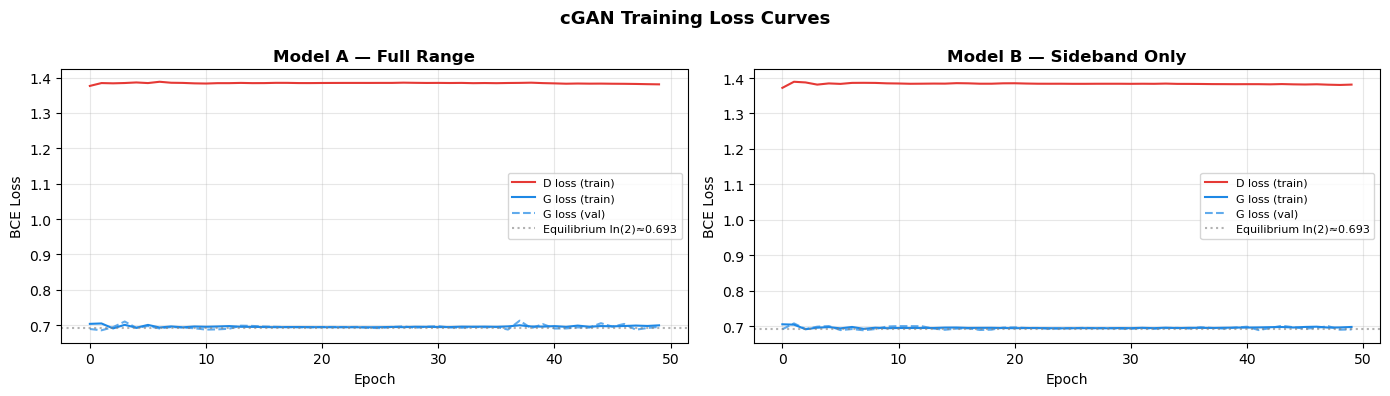

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, hist, title in zip(axes, [hist_A, hist_B],
                            ["Model A — Full Range", "Model B — Sideband Only"]):
    ax.plot(hist["lossD_train"], color="#E53935", linewidth=1.5, label="D loss (train)")
    ax.plot(hist["lossG_train"], color="#1E88E5", linewidth=1.5, label="G loss (train)")
    ax.plot(hist["lossG_val"],   color="#1E88E5", linewidth=1.5, linestyle="--",
            alpha=0.7, label="G loss (val)")
    ax.axhline(np.log(2), color="gray", linestyle=":", alpha=0.6,
               label=f"Equilibrium ln(2)≈{np.log(2):.3f}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss")
    ax.set_title(title, fontweight="bold"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle("cGAN Training Loss Curves", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("training_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 11. Closure Tests

Generate background mass samples from both models and overlay with real background.

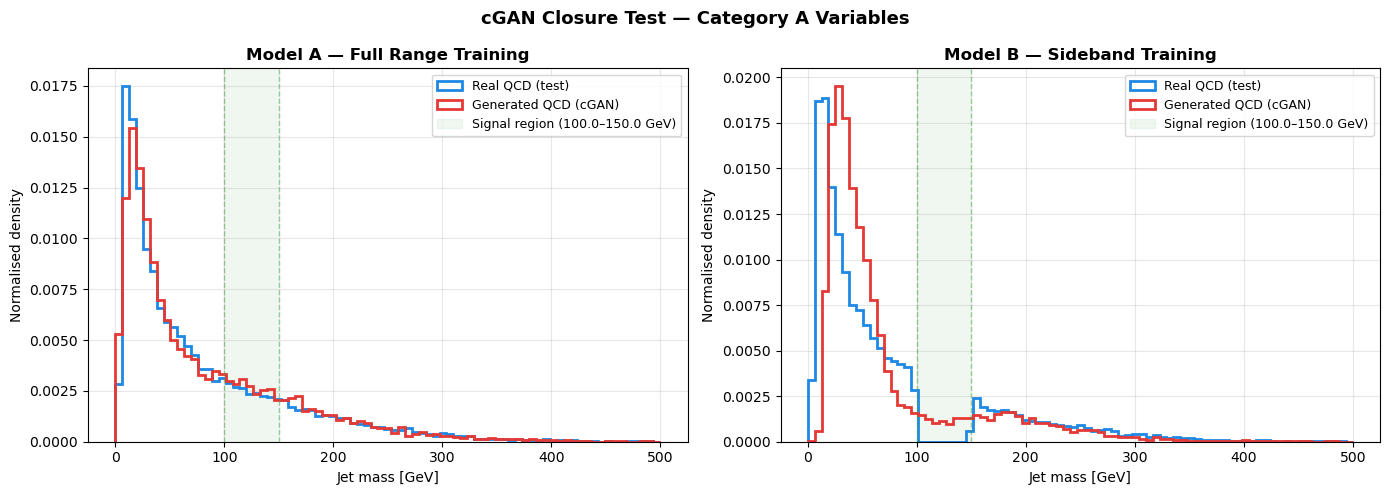

In [45]:
# Alias: test sets are already scaled inside make_splits
XA_te_s = XA_te
XB_te_s = XB_te

fake_A = generate_mass(G_A, XA_te_s, sy_A, device)
fake_B = generate_mass(G_B, XB_te_s, sy_B, device)

bins = np.linspace(0, 500, 80)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, real, fake, title in zip(
        axes, [yA_te, yB_te], [fake_A, fake_B],
        ["Model A — Full Range Training",
         "Model B — Sideband Training"]):
    ax.hist(real, bins=bins, density=True, histtype="step",
            linewidth=2, color="#1E88E5", label="Real QCD (test)")
    ax.hist(fake, bins=bins, density=True, histtype="step",
            linewidth=2, color="#E53935", label="Generated QCD (cGAN)")
    ax.axvspan(SIGNAL_LO, SIGNAL_HI, alpha=0.08, color="#43A047",
               label=f"Signal region ({SIGNAL_LO}–{SIGNAL_HI} GeV)")
    ax.axvline(SIGNAL_LO, color="#43A047", linewidth=1, linestyle="--", alpha=0.5)
    ax.axvline(SIGNAL_HI, color="#43A047", linewidth=1, linestyle="--", alpha=0.5)
    ax.set_xlabel("Jet mass [GeV]"); ax.set_ylabel("Normalised density")
    ax.set_title(title, fontweight="bold"); ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.suptitle("cGAN Closure Test — Category A Variables", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("closure_plots.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 12. Signal Region Study — Full Range vs Sideband

This is the key comparison motivated by the supervisor's suggestion.

**Question:** Does excluding the signal region during training change the model's behaviour in that region?

**Method:** Evaluate both models on the **same set of events in the signal region** (100–150 GeV),  
using the full-range test set (which includes signal region events).

**Interpretation:**
- **Large difference** → the signal region data influences the model → sideband training is essential  
- **Small difference** → the model can extrapolate safely from sidebands → validates the approach

In [46]:
# Evaluate both models on full-range test set for fair comparison
# Use Model A's test set (full range) — contains signal region events
fake_A_full = generate_mass(G_A, XA_te_s, sy_A, device)

# Apply Model B to the full-range test features (rescaled with B's scaler)
XA_te_rescaled = sX_B.transform(
    sX_A.inverse_transform(XA_te_s)  # back to GeV → rescale with B's scaler
).astype(np.float32)
fake_B_on_full = generate_mass(G_B, XA_te_rescaled, sy_B, device)

# Isolate signal region events
sig_mask = (yA_te >= SIGNAL_LO) & (yA_te <= SIGNAL_HI)
real_sig  = yA_te[sig_mask]
fake_A_sig = fake_A_full[sig_mask]
fake_B_sig = fake_B_on_full[sig_mask]

print(f"Events in signal region (test set): {sig_mask.sum():,}")

# KS test in signal region
ks_A_sig, _ = ks_2samp(real_sig, fake_A_sig)
ks_B_sig, _ = ks_2samp(real_sig, fake_B_sig)

print(f"\nKS in signal region ({SIGNAL_LO}–{SIGNAL_HI} GeV):")
print(f"  Model A (full range training) : KS = {ks_A_sig:.4f}")
print(f"  Model B (sideband training)   : KS = {ks_B_sig:.4f}")

diff = abs(ks_A_sig - ks_B_sig)
print(f"\nDifference: {diff:.4f}")
if diff > 0.05:
    print("→ Significant difference: signal region data affects the model.")
    print("  Sideband training is important to avoid bias.")
else:
    print("→ Small difference: the model extrapolates well from sideband to signal region.")
    print("  Sideband training is validated as a robust approach.")

Events in signal region (test set): 1,482

KS in signal region (100.0–150.0 GeV):
  Model A (full range training) : KS = 0.3252
  Model B (sideband training)   : KS = 0.4069

Difference: 0.0816
→ Significant difference: signal region data affects the model.
  Sideband training is important to avoid bias.


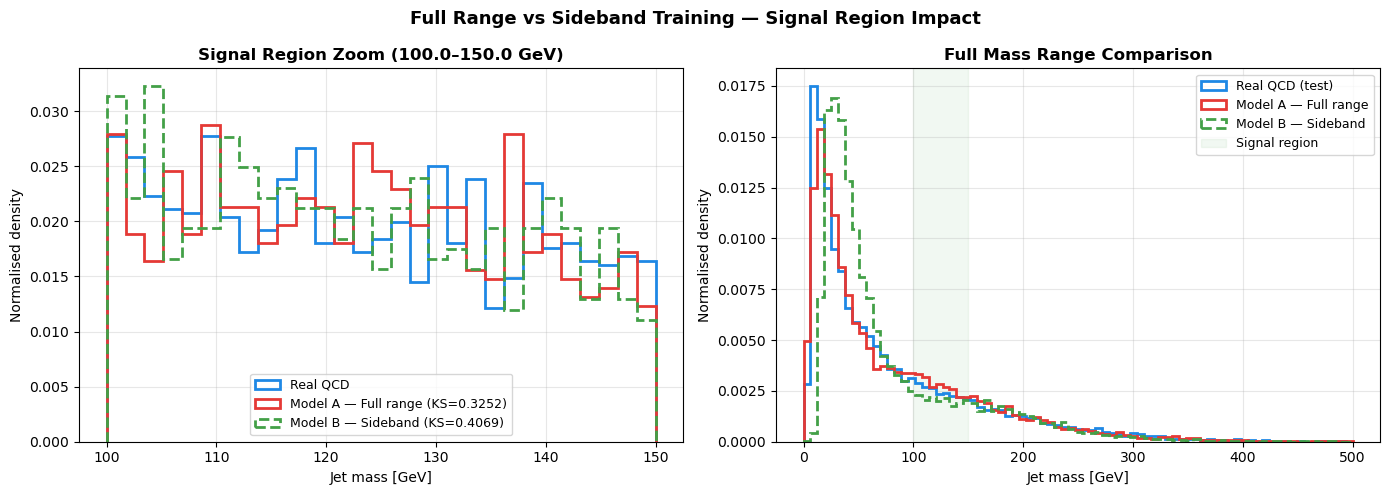

In [47]:
# Comparison plot: signal region zoom
bins_sig = np.linspace(SIGNAL_LO, SIGNAL_HI, 30)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: signal region zoom
ax = axes[0]
ax.hist(real_sig,   bins=bins_sig, density=True, histtype="step",
        linewidth=2, color="#1E88E5", label="Real QCD")
ax.hist(fake_A_sig, bins=bins_sig, density=True, histtype="step",
        linewidth=2, color="#E53935", linestyle="-",
        label=f"Model A — Full range (KS={ks_A_sig:.4f})")
ax.hist(fake_B_sig, bins=bins_sig, density=True, histtype="step",
        linewidth=2, color="#43A047", linestyle="--",
        label=f"Model B — Sideband (KS={ks_B_sig:.4f})")
ax.set_xlabel("Jet mass [GeV]"); ax.set_ylabel("Normalised density")
ax.set_title(f"Signal Region Zoom ({SIGNAL_LO}–{SIGNAL_HI} GeV)", fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Right: full range comparison
ax2 = axes[1]
bins_full = np.linspace(0, 500, 80)
ax2.hist(yA_te,         bins=bins_full, density=True, histtype="step",
         linewidth=2, color="#1E88E5", label="Real QCD (test)")
ax2.hist(fake_A_full,   bins=bins_full, density=True, histtype="step",
         linewidth=2, color="#E53935", linestyle="-",
         label="Model A — Full range")
ax2.hist(fake_B_on_full, bins=bins_full, density=True, histtype="step",
         linewidth=2, color="#43A047", linestyle="--",
         label="Model B — Sideband")
ax2.axvspan(SIGNAL_LO, SIGNAL_HI, alpha=0.07, color="#43A047", label="Signal region")
ax2.set_xlabel("Jet mass [GeV]"); ax2.set_ylabel("Normalised density")
ax2.set_title("Full Mass Range Comparison", fontweight="bold")
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)

plt.suptitle("Full Range vs Sideband Training — Signal Region Impact",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("signal_region_study.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 13. Quantitative Evaluation — KS Test (Multi-Seed)

Both models are evaluated over 3 random seeds to account for GAN training stochasticity.  
We report **mean ± standard deviation** of the KS statistic.

In [48]:
def eval_multiseed(X_tr, y_tr, X_va, y_va, X_te, y_te, scaler_y,
                   n_vars, label, seeds=[42, 123, 456], epochs=50):
    ks_list = []
    print(f"\n{label}")
    print(f"  {'Seed':>6}  {'KS':>8}")
    for seed in seeds:
        G_tmp, dev_tmp, _ = train_cgan(X_tr, y_tr, X_va, y_va,
                                        n_vars=n_vars, epochs=epochs, seed=seed)
        fake_tmp = generate_mass(G_tmp, X_te, scaler_y, dev_tmp)
        ks, _ = ks_2samp(y_te, fake_tmp)
        ks_list.append(ks)
        print(f"  {seed:>6}  {ks:>8.4f}")
    m, s = np.mean(ks_list), np.std(ks_list)
    print(f"  Mean ± std : {m:.4f} ± {s:.4f}")
    return m, s

ksA_mean, ksA_std = eval_multiseed(XA_tr, yA_tr, XA_va, yA_va, XA_te_s, yA_te,
                                    sy_A, n_vars, "Model A — Full Range")
ksB_mean, ksB_std = eval_multiseed(XB_tr, yB_tr, XB_va, yB_va, XB_te_s, yB_te,
                                    sy_B, n_vars, "Model B — Sideband")

print(f"\n{'='*52}")
print(f"{'Model':<30} {'KS mean':>9} {'KS std':>9}")
print(f"{'-'*52}")
print(f"{'Model A: Full range':<30} {ksA_mean:>9.4f} {ksA_std:>9.4f}")
print(f"{'Model B: Sideband':<30} {ksB_mean:>9.4f} {ksB_std:>9.4f}")
print(f"{'='*52}")


Model A — Full Range
    Seed        KS
Epoch   1/50  D=1.3764  G=0.7036  G_val=0.6891
Epoch  10/50  D=1.3836  G=0.6962  G_val=0.6912
Epoch  20/50  D=1.3844  G=0.6944  G_val=0.6938
Epoch  30/50  D=1.3847  G=0.6951  G_val=0.6956
Epoch  40/50  D=1.3843  G=0.6958  G_val=0.7029
Epoch  50/50  D=1.3808  G=0.6994  G_val=0.6951
      42    0.0253
Epoch   1/50  D=1.3824  G=0.6951  G_val=0.6935
Epoch  10/50  D=1.3858  G=0.6960  G_val=0.6986
Epoch  20/50  D=1.3849  G=0.6942  G_val=0.6940
Epoch  30/50  D=1.3846  G=0.6952  G_val=0.6942
Epoch  40/50  D=1.3840  G=0.6949  G_val=0.7050
Epoch  50/50  D=1.3825  G=0.6960  G_val=0.6965
     123    0.0531
Epoch   1/50  D=1.3817  G=0.6912  G_val=0.6966
Epoch  10/50  D=1.3850  G=0.6968  G_val=0.6913
Epoch  20/50  D=1.3846  G=0.6942  G_val=0.6946
Epoch  30/50  D=1.3843  G=0.6954  G_val=0.6928
Epoch  40/50  D=1.3835  G=0.6964  G_val=0.6962
Epoch  50/50  D=1.3828  G=0.6976  G_val=0.6942
     456    0.1897
  Mean ± std : 0.0894 ± 0.0718

Model B — Sideband
    S

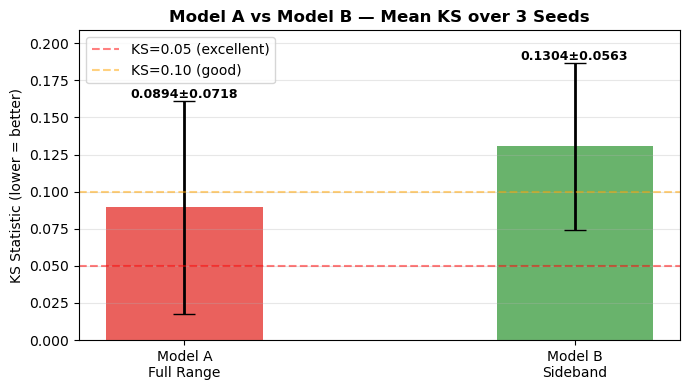

In [49]:
# Summary bar chart with error bars
fig, ax = plt.subplots(figsize=(7, 4))
labels_bar = ["Model A\nFull Range", "Model B\nSideband"]
means_bar  = [ksA_mean, ksB_mean]
stds_bar   = [ksA_std,  ksB_std]

bars = ax.bar(labels_bar, means_bar, yerr=stds_bar,
              color=["#E53935", "#43A047"], alpha=0.8, width=0.4,
              capsize=8, error_kw={"linewidth": 2})
ax.axhline(0.05, color="red",    linestyle="--", alpha=0.5, label="KS=0.05 (excellent)")
ax.axhline(0.10, color="orange", linestyle="--", alpha=0.5, label="KS=0.10 (good)")
for bar, m, s in zip(bars, means_bar, stds_bar):
    ax.text(bar.get_x() + bar.get_width()/2, m + s + 0.002,
            f"{m:.4f}±{s:.4f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("KS Statistic (lower = better)")
ax.set_title("Model A vs Model B — Mean KS over 3 Seeds", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(means_bar) * 1.6)
plt.tight_layout()
plt.savefig("ks_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 14. Ablation Study — Optimal Number of Conditioning Variables

Variables are added one by one in order of correlation strength (strongest first).  
Both full-range and sideband training are tested at each checkpoint.  
Each point is averaged over 3 seeds.

In [50]:
# Corrected Category A variables in correlation order
ablation_ordered = [v for v in [
    "ecf2", "split12", "qw", "ghosttrackcount",
    "ghostantiktvr30rmax4rmin02pv0trackjetscount",
    "split23", "split34", "ecf3", "foxwolfram2", "foxwolfram4",
    "zg", "zcut12", "tau21", "tau21_wta", "d2",
    "n2", "thrustmin", "zcut23", "thrustmaj", "aplanarity", "sphericity"
] if v in leading]

# Checkpoints to evaluate
checkpoints = [1, 2, 3, 4, 6, 10, len(ablation_ordered)]
checkpoints = sorted(set(checkpoints))

results_full = []  # (n, last_var, ks_mean, ks_std) — full range
results_sb   = []  # (n, last_var, ks_mean, ks_std) — sideband

print(f"{'N':>4}  {'Last var':<45}  {'KS_full':>8}  {'KS_sb':>8}")
print("-" * 72)

for n in checkpoints:
    vars_n = ablation_ordered[:n]
    mass_a = leading["mass"].astype(np.float32)
    X_a    = np.column_stack([leading[v] for v in vars_n]).astype(np.float32)
    mask_a = np.isfinite(mass_a) & np.all(np.isfinite(X_a), axis=1) & (mass_a > 0)
    X_a    = X_a[mask_a]; y_a = mass_a[mask_a]
    sb_a   = (y_a < SIGNAL_LO) | (y_a > SIGNAL_HI)
    X_sb_a = X_a[sb_a]; y_sb_a = y_a[sb_a]

    def run_seeds(X, y):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.15, random_state=42)
        Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=0.17647, random_state=42)
        sX = StandardScaler(); sy = StandardScaler()
        Xtr_s = sX.fit_transform(Xtr).astype(np.float32)
        Xva_s = sX.transform(Xva).astype(np.float32)
        Xte_s = sX.transform(Xte).astype(np.float32)
        ytr_s = sy.fit_transform(ytr.reshape(-1,1)).astype(np.float32).squeeze()
        yva_s = sy.transform(yva.reshape(-1,1)).astype(np.float32).squeeze()
        ks_runs = []
        for seed in [42, 123, 456]:
            G_t, dev_t, _ = train_cgan(Xtr_s, ytr_s, Xva_s, yva_s,
                                        n_vars=n, epochs=50, seed=seed)
            fake_t = generate_mass(G_t, Xte_s, sy, dev_t)
            ks_t, _ = ks_2samp(yte, fake_t)
            ks_runs.append(ks_t)
        return np.mean(ks_runs), np.std(ks_runs)

    m_f, s_f = run_seeds(X_a, y_a)
    m_s, s_b = run_seeds(X_sb_a, y_sb_a)

    results_full.append((n, vars_n[-1], m_f, s_f))
    results_sb.append((n, vars_n[-1], m_s, s_b))
    print(f"{n:>4}  {vars_n[-1]:<45}  {m_f:>8.4f}  {m_s:>8.4f}")

print("-" * 72)

   N  Last var                                        KS_full     KS_sb
------------------------------------------------------------------------
Epoch   1/50  D=1.3139  G=0.7240  G_val=0.7316
Epoch  10/50  D=1.3829  G=0.6961  G_val=0.6958
Epoch  20/50  D=1.3831  G=0.6955  G_val=0.6915
Epoch  30/50  D=1.3842  G=0.6964  G_val=0.7012
Epoch  40/50  D=1.3848  G=0.6950  G_val=0.6966
Epoch  50/50  D=1.3854  G=0.6962  G_val=0.7050
Epoch   1/50  D=1.3325  G=0.7129  G_val=0.7000
Epoch  10/50  D=1.3854  G=0.6952  G_val=0.6966
Epoch  20/50  D=1.3848  G=0.6945  G_val=0.6919
Epoch  30/50  D=1.3857  G=0.6961  G_val=0.6970
Epoch  40/50  D=1.3859  G=0.6943  G_val=0.6990
Epoch  50/50  D=1.3859  G=0.6947  G_val=0.6882
Epoch   1/50  D=1.3413  G=0.7102  G_val=0.7245
Epoch  10/50  D=1.3825  G=0.6960  G_val=0.6953
Epoch  20/50  D=1.3847  G=0.6946  G_val=0.6918
Epoch  30/50  D=1.3847  G=0.6958  G_val=0.6936
Epoch  40/50  D=1.3849  G=0.6946  G_val=0.6923
Epoch  50/50  D=1.3854  G=0.6949  G_val=0.6866
Epoch   1

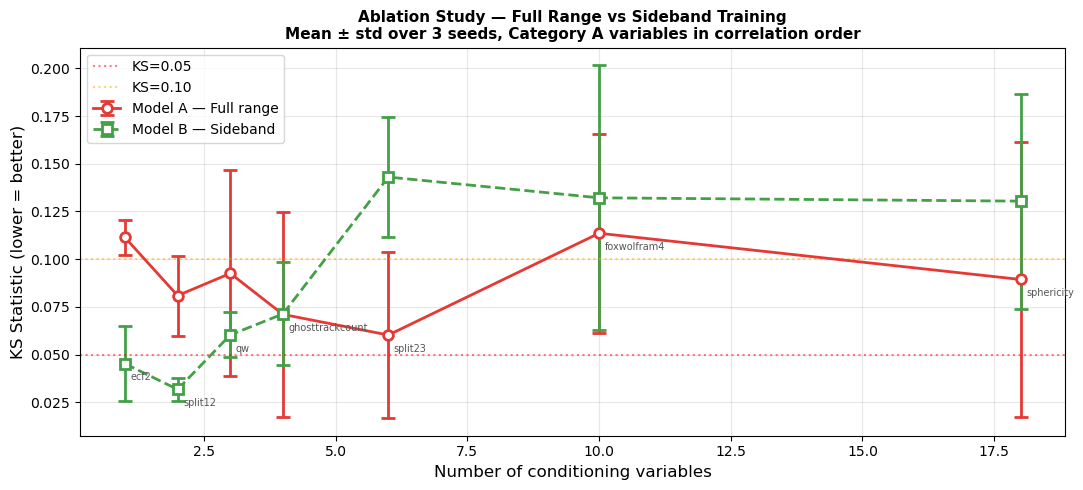

Best config — Full range : 6 vars  KS=0.0602
Best config — Sideband   : 2 vars  KS=0.0318


In [51]:
ns     = [r[0] for r in results_full]
mf     = [r[2] for r in results_full]
sf     = [r[3] for r in results_full]
ms     = [r[2] for r in results_sb]
ss     = [r[3] for r in results_sb]
labels_abl = [r[1] for r in results_full]

fig, ax = plt.subplots(figsize=(11, 5))
ax.errorbar(ns, mf, yerr=sf, fmt='o-', color="#E53935", linewidth=2,
            markersize=7, capsize=5, markerfacecolor="white", markeredgewidth=2,
            label="Model A — Full range")
ax.errorbar(ns, ms, yerr=ss, fmt='s--', color="#43A047", linewidth=2,
            markersize=7, capsize=5, markerfacecolor="white", markeredgewidth=2,
            label="Model B — Sideband")
for x, yf, ys, lab in zip(ns, mf, ms, labels_abl):
    ax.annotate(lab, (x, min(yf, ys)), xytext=(4, -12),
                textcoords="offset points", fontsize=7, color="#555")
ax.axhline(0.05, color="red",    linestyle=":", alpha=0.5, label="KS=0.05")
ax.axhline(0.10, color="orange", linestyle=":", alpha=0.5, label="KS=0.10")
ax.set_xlabel("Number of conditioning variables", fontsize=12)
ax.set_ylabel("KS Statistic (lower = better)", fontsize=12)
ax.set_title("Ablation Study — Full Range vs Sideband Training\n"
             "Mean ± std over 3 seeds, Category A variables in correlation order",
             fontsize=11, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_study.png", dpi=150, bbox_inches="tight")
plt.show()

best_f = ns[int(np.argmin(mf))]
best_s = ns[int(np.argmin(ms))]
print(f"Best config — Full range : {best_f} vars  KS={min(mf):.4f}")
print(f"Best config — Sideband   : {best_s} vars  KS={min(ms):.4f}")

---
## 15. Comparison with Traditional Method — Exponential Fit

The traditional background modelling approach fits a smooth analytical function to the mass  
distribution. We use an exponential fit as the baseline:

$$f(m) = A \cdot e^{-bm}$$

Comparing the KS statistic of the cGAN against this baseline quantifies the improvement.

Exponential fit: A=0.0153  b=0.01438

Summary:
  Exponential fit KS          : 0.0801
  Model A (full range) KS     : 0.0894 ± 0.0718
  Model B (sideband)   KS     : 0.1304 ± 0.0563


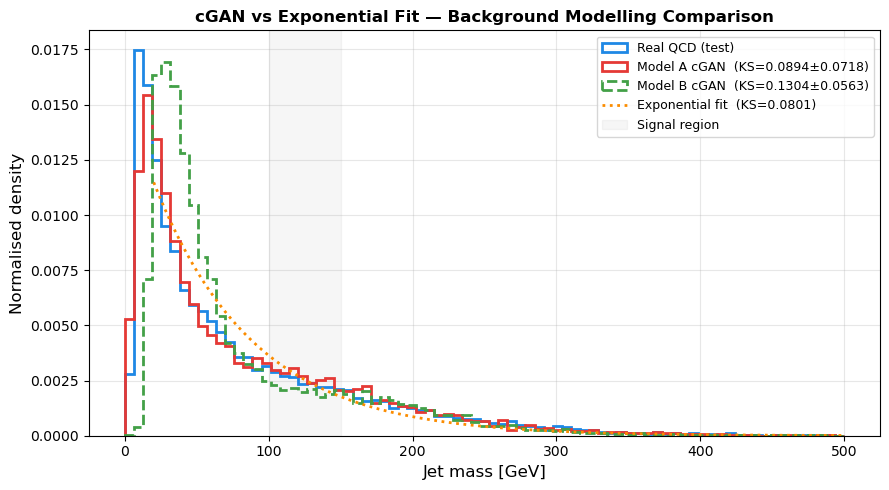

In [54]:
from scipy.optimize import curve_fit

def exp_model(m, A, b):
    return A * np.exp(-b * m)

# Fit to the sideband test set
sb_mask_te = (yA_te < SIGNAL_LO) | (yA_te > SIGNAL_HI)
y_te_sb    = yA_te[sb_mask_te]

counts, edges = np.histogram(y_te_sb, bins=60, density=True)
centres = 0.5 * (edges[:-1] + edges[1:])
nz = counts > 0
popt, _ = curve_fit(exp_model, centres[nz], counts[nz], p0=[0.05, 0.01], maxfev=5000)

# Sample from exponential for KS comparison
rng = np.random.default_rng(42)
exp_samp = rng.exponential(1.0/popt[1], size=len(y_te_sb)*5)
exp_samp = exp_samp[(exp_samp >= y_te_sb.min()) & (exp_samp <= y_te_sb.max())][:len(y_te_sb)]
ks_exp, _ = ks_2samp(y_te_sb, exp_samp)

print(f"Exponential fit: A={popt[0]:.4f}  b={popt[1]:.5f}")
print(f"\nSummary:")
print(f"  Exponential fit KS          : {ks_exp:.4f}")
print(f"  Model A (full range) KS     : {ksA_mean:.4f} ± {ksA_std:.4f}")
print(f"  Model B (sideband)   KS     : {ksB_mean:.4f} ± {ksB_std:.4f}")

bins = np.linspace(0, 500, 80)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(yA_te, bins=bins, density=True, histtype="step",
        linewidth=2, color="#1E88E5", label="Real QCD (test)")
ax.hist(fake_A, bins=bins, density=True, histtype="step",
        linewidth=2, color="#E53935", label=f"Model A cGAN  (KS={ksA_mean:.4f}±{ksA_std:.4f})")
ax.hist(fake_B_on_full, bins=bins, density=True, histtype="step",
        linewidth=2, color="#43A047", linestyle="--",
        label=f"Model B cGAN  (KS={ksB_mean:.4f}±{ksB_std:.4f})")
m_plot = np.linspace(20, 500, 500)
ax.plot(m_plot, exp_model(m_plot, *popt), color="#FB8C00", linewidth=2, linestyle=":",
        label=f"Exponential fit  (KS={ks_exp:.4f})")
ax.axvspan(SIGNAL_LO, SIGNAL_HI, alpha=0.07, color="gray", label="Signal region")
ax.set_xlabel("Jet mass [GeV]", fontsize=12)
ax.set_ylabel("Normalised density", fontsize=12)
ax.set_title("cGAN vs Exponential Fit — Background Modelling Comparison",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("comparison_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 16. Save Results

In [55]:
np.savez("cgan_final_results.npz",
    fake_A=fake_A,              real_A=yA_te,
    fake_B=fake_B_on_full,      real_B=yA_te,
    fake_A_sig=fake_A_sig,      fake_B_sig=fake_B_sig,  real_sig=real_sig,
    ks_A_mean=ksA_mean,         ks_A_std=ksA_std,
    ks_B_mean=ksB_mean,         ks_B_std=ksB_std,
    ks_A_signal=ks_A_sig,       ks_B_signal=ks_B_sig,
    # ks_exponential=ks_exp,
    category_a_vars=np.array(category_a_vars, dtype=object),
    n_vars=n_vars,
    signal_lo=SIGNAL_LO,        signal_hi=SIGNAL_HI,
)

print("Saved: cgan_final_results.npz")
print()
print("=" * 58)
print("FINAL SUMMARY")
print("=" * 58)
print(f"  Category A variables used    : {n_vars}")
print(f"  Signal region (blind)        : {SIGNAL_LO}–{SIGNAL_HI} GeV")
print(f"  Model A KS (full range)      : {ksA_mean:.4f} ± {ksA_std:.4f}")
print(f"  Model B KS (sideband)        : {ksB_mean:.4f} ± {ksB_std:.4f}")
print(f"  Signal region — Model A KS   : {ks_A_sig:.4f}")
print(f"  Signal region — Model B KS   : {ks_B_sig:.4f}")
# print(f"  Exponential fit KS           : {ks_exp:.4f}")
print("=" * 58)

Saved: cgan_final_results.npz

FINAL SUMMARY
  Category A variables used    : 18
  Signal region (blind)        : 100.0–150.0 GeV
  Model A KS (full range)      : 0.0894 ± 0.0718
  Model B KS (sideband)        : 0.1304 ± 0.0563
  Signal region — Model A KS   : 0.3252
  Signal region — Model B KS   : 0.4069


Final model configuration:
  Variables : ['ecf2', 'split12']
  Blind region: 100.0–150.0 GeV
  Training  : sideband only

Full dataset  : 79,997 events
Sideband only : 70,049 events

Train: 49,033  Val: 10,508  Test: 10,508

  Seed   KS (sideband)
-------------------------
Epoch   1/50  D=1.3357  G=0.6992  G_val=0.6929
Epoch  10/50  D=1.3783  G=0.6978  G_val=0.6967
Epoch  20/50  D=1.3783  G=0.6989  G_val=0.6933
Epoch  30/50  D=1.3749  G=0.7037  G_val=0.7075
Epoch  40/50  D=1.3731  G=0.7065  G_val=0.7014
Epoch  50/50  D=1.3729  G=0.7065  G_val=0.7081
    42          0.0283
Epoch   1/50  D=1.3577  G=0.7049  G_val=0.6899
Epoch  10/50  D=1.3823  G=0.6960  G_val=0.6952
Epoch  20/50  D=1.3812  G=0.6974  G_val=0.6933
Epoch  30/50  D=1.3781  G=0.7005  G_val=0.7085
Epoch  40/50  D=1.3770  G=0.7005  G_val=0.6970
Epoch  50/50  D=1.3762  G=0.7010  G_val=0.7011
   123          0.0403
Epoch   1/50  D=1.3637  G=0.7106  G_val=0.6915
Epoch  10/50  D=1.3804  G=0.6972  G_val=0.6967
Epoch  20/50  D=1.3816

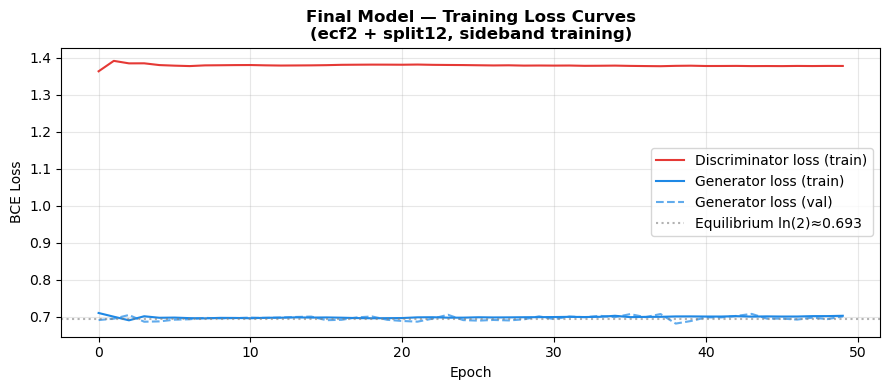

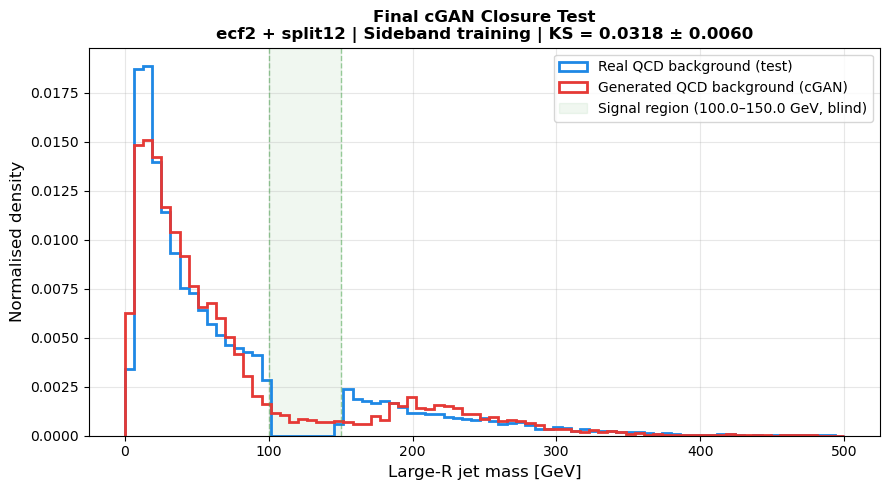


Signal region (100.0–150.0 GeV):
  Events       : 9,948
  KS statistic : 0.4802


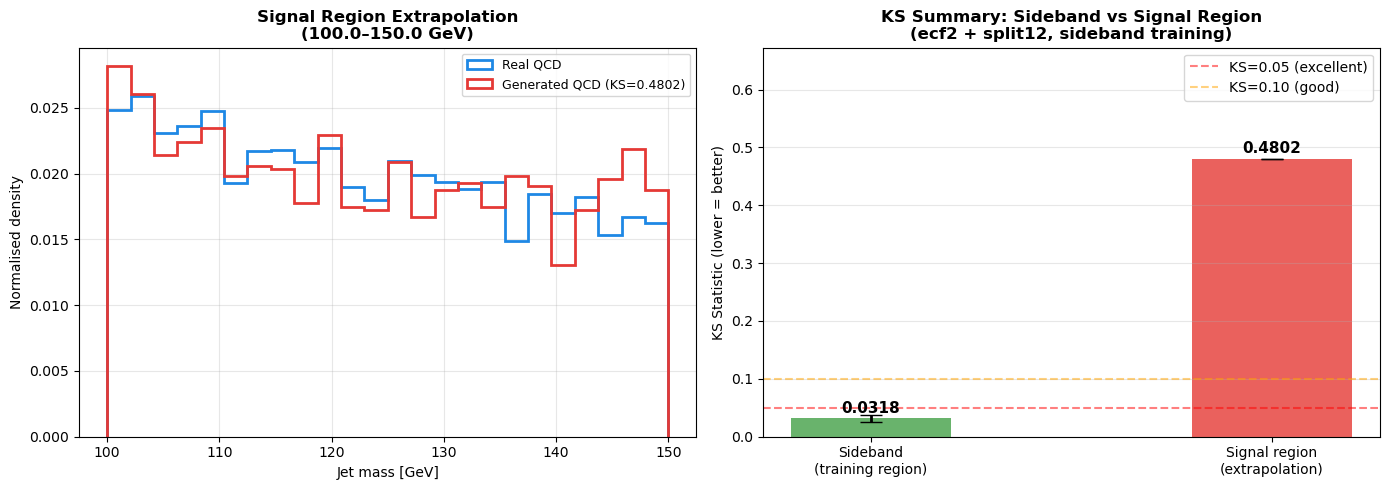


FINAL MODEL SUMMARY
  Variables             : ecf2 + split12 (2 vars)
  Training region       : sideband (< 100.0 or > 150.0 GeV)
  Sideband KS (mean±std): 0.0318 ± 0.0060
  Signal region KS      : 0.4802  [out-of-distribution extrapolation]


In [57]:
# ═══════════════════════════════════════════════════════════
# FINAL MODEL: Optimal Configuration
# - Sideband training (100–150 GeV blind)
# - 2 conditioning variables: ecf2 + split12
# - 3-seed averaged KS evaluation
# ═══════════════════════════════════════════════════════════

SIGNAL_LO_FINAL = 100.0
SIGNAL_HI_FINAL = 150.0
FINAL_VARS = ["ecf2", "split12"]

print(f"Final model configuration:")
print(f"  Variables : {FINAL_VARS}")
print(f"  Blind region: {SIGNAL_LO_FINAL}–{SIGNAL_HI_FINAL} GeV")
print(f"  Training  : sideband only")

# ── Build dataset ──────────────────────────────────────────
mass_f = leading["mass"].astype(np.float32)
X_f    = np.column_stack([leading[v] for v in FINAL_VARS]).astype(np.float32)

mask_f = np.isfinite(mass_f) & np.all(np.isfinite(X_f), axis=1) & (mass_f > 0)
X_f    = X_f[mask_f]
y_f    = mass_f[mask_f]

# Sideband only
sb_f   = (y_f < SIGNAL_LO_FINAL) | (y_f > SIGNAL_HI_FINAL)
X_f_sb = X_f[sb_f]
y_f_sb = y_f[sb_f]

print(f"\nFull dataset  : {len(y_f):,} events")
print(f"Sideband only : {len(y_f_sb):,} events")

# ── Split + Scale ──────────────────────────────────────────
Xf_tv, Xf_te, yf_tv, yf_te = train_test_split(
    X_f_sb, y_f_sb, test_size=0.15, random_state=42)
Xf_tr, Xf_va, yf_tr, yf_va = train_test_split(
    Xf_tv, yf_tv, test_size=0.17647, random_state=42)

sXf = StandardScaler(); syf = StandardScaler()
Xf_tr_s = sXf.fit_transform(Xf_tr).astype(np.float32)
Xf_va_s = sXf.transform(Xf_va).astype(np.float32)
Xf_te_s = sXf.transform(Xf_te).astype(np.float32)
yf_tr_s = syf.fit_transform(yf_tr.reshape(-1,1)).astype(np.float32).squeeze()
yf_va_s = syf.transform(yf_va.reshape(-1,1)).astype(np.float32).squeeze()

print(f"\nTrain: {len(yf_tr):,}  Val: {len(yf_va):,}  Test: {len(yf_te):,}")

# ── Train 3 seeds ──────────────────────────────────────────
seeds_final = [42, 123, 456]
ks_final    = []
G_models    = []

print(f"\n{'Seed':>6}  {'KS (sideband)':>14}")
print("-" * 25)

for seed in seeds_final:
    G_f, dev_f, hist_f = train_cgan(
        Xf_tr_s, yf_tr_s, Xf_va_s, yf_va_s,
        n_vars=2, epochs=50, seed=seed)
    fake_f  = generate_mass(G_f, Xf_te_s, syf, dev_f)
    ks_f, _ = ks_2samp(yf_te, fake_f)
    ks_final.append(ks_f)
    G_models.append((G_f, dev_f, hist_f))
    print(f"{seed:>6}  {ks_f:>14.4f}")

ks_final_mean = np.mean(ks_final)
ks_final_std  = np.std(ks_final)
print(f"\nFinal KS (sideband) = {ks_final_mean:.4f} ± {ks_final_std:.4f}")

# ── Use best seed for plots ────────────────────────────────
best_seed_idx = int(np.argmin(ks_final))
G_best, dev_best, hist_best = G_models[best_seed_idx]
print(f"Using seed={seeds_final[best_seed_idx]} for plots (KS={ks_final[best_seed_idx]:.4f})")

# ── Loss curve ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist_best["lossD_train"], color="#E53935", linewidth=1.5,
        label="Discriminator loss (train)")
ax.plot(hist_best["lossG_train"], color="#1E88E5", linewidth=1.5,
        label="Generator loss (train)")
ax.plot(hist_best["lossG_val"],   color="#1E88E5", linewidth=1.5,
        linestyle="--", alpha=0.7, label="Generator loss (val)")
ax.axhline(np.log(2), color="gray", linestyle=":", alpha=0.6,
           label=f"Equilibrium ln(2)≈{np.log(2):.3f}")
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss")
ax.set_title("Final Model — Training Loss Curves\n(ecf2 + split12, sideband training)",
             fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("final_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Closure plot (full range) ──────────────────────────────
fake_best = generate_mass(G_best, Xf_te_s, syf, dev_best)
bins = np.linspace(0, 500, 80)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(yf_te,    bins=bins, density=True, histtype="step",
        linewidth=2, color="#1E88E5", label="Real QCD background (test)")
ax.hist(fake_best, bins=bins, density=True, histtype="step",
        linewidth=2, color="#E53935", label="Generated QCD background (cGAN)")
ax.axvspan(SIGNAL_LO_FINAL, SIGNAL_HI_FINAL, alpha=0.08, color="#43A047",
           label=f"Signal region ({SIGNAL_LO_FINAL}–{SIGNAL_HI_FINAL} GeV, blind)")
ax.axvline(SIGNAL_LO_FINAL, color="#43A047", linewidth=1, linestyle="--", alpha=0.5)
ax.axvline(SIGNAL_HI_FINAL, color="#43A047", linewidth=1, linestyle="--", alpha=0.5)
ax.set_xlabel("Large-R jet mass [GeV]", fontsize=12)
ax.set_ylabel("Normalised density", fontsize=12)
ax.set_title(f"Final cGAN Closure Test\n"
             f"ecf2 + split12 | Sideband training | KS = {ks_final_mean:.4f} ± {ks_final_std:.4f}",
             fontweight="bold")
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("final_closure_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Signal region KS ───────────────────────────────────────
# Apply final model to full dataset to get signal region predictions
X_full_2var = np.column_stack([leading[v] for v in FINAL_VARS]).astype(np.float32)
mask_full   = np.isfinite(y_f) & np.all(np.isfinite(X_full_2var[mask_f]), axis=1)

# Scale full dataset with sideband scaler
X_full_2var_clean = X_full_2var[mask_f]
X_full_scaled     = sXf.transform(X_full_2var_clean).astype(np.float32)
fake_full          = generate_mass(G_best, X_full_scaled, syf, dev_best)

# Isolate signal region
sig_mask_f  = (y_f >= SIGNAL_LO_FINAL) & (y_f <= SIGNAL_HI_FINAL)
real_sig_f  = y_f[sig_mask_f]
fake_sig_f  = fake_full[sig_mask_f]

ks_sig_f, _ = ks_2samp(real_sig_f, fake_sig_f)

print(f"\nSignal region ({SIGNAL_LO_FINAL}–{SIGNAL_HI_FINAL} GeV):")
print(f"  Events       : {sig_mask_f.sum():,}")
print(f"  KS statistic : {ks_sig_f:.4f}")

# Signal region zoom plot
bins_sig = np.linspace(SIGNAL_LO_FINAL, SIGNAL_HI_FINAL, 25)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: signal region zoom
ax = axes[0]
ax.hist(real_sig_f, bins=bins_sig, density=True, histtype="step",
        linewidth=2, color="#1E88E5", label="Real QCD")
ax.hist(fake_sig_f, bins=bins_sig, density=True, histtype="step",
        linewidth=2, color="#E53935",
        label=f"Generated QCD (KS={ks_sig_f:.4f})")
ax.set_xlabel("Jet mass [GeV]"); ax.set_ylabel("Normalised density")
ax.set_title(f"Signal Region Extrapolation\n({SIGNAL_LO_FINAL}–{SIGNAL_HI_FINAL} GeV)",
             fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Right: summary KS bar
ax2 = axes[1]
bar_labels = ["Sideband\n(training region)", "Signal region\n(extrapolation)"]
bar_vals   = [ks_final_mean, ks_sig_f]
bar_errs   = [ks_final_std, 0]
colors     = ["#43A047", "#E53935"]
bars = ax2.bar(bar_labels, bar_vals, yerr=bar_errs,
               color=colors, alpha=0.8, width=0.4,
               capsize=8, error_kw={"linewidth": 2})
ax2.axhline(0.05, color="red",    linestyle="--", alpha=0.5, label="KS=0.05 (excellent)")
ax2.axhline(0.10, color="orange", linestyle="--", alpha=0.5, label="KS=0.10 (good)")
for bar, val in zip(bars, bar_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f"{val:.4f}", ha="center", fontsize=11, fontweight="bold")
ax2.set_ylabel("KS Statistic (lower = better)")
ax2.set_title("KS Summary: Sideband vs Signal Region\n(ecf2 + split12, sideband training)",
              fontweight="bold")
ax2.legend(); ax2.grid(axis="y", alpha=0.3)
ax2.set_ylim(0, max(bar_vals) * 1.4)
plt.tight_layout()
plt.savefig("final_signal_region_ks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Final summary ──────────────────────────────────────────
print()
print("=" * 55)
print("FINAL MODEL SUMMARY")
print("=" * 55)
print(f"  Variables             : ecf2 + split12 (2 vars)")
print(f"  Training region       : sideband (< {SIGNAL_LO_FINAL} or > {SIGNAL_HI_FINAL} GeV)")
print(f"  Sideband KS (mean±std): {ks_final_mean:.4f} ± {ks_final_std:.4f}")
print(f"  Signal region KS      : {ks_sig_f:.4f}  [out-of-distribution extrapolation]")
print("=" * 55)